In [1]:
from pathlib import Path

import cmocean as cmo
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D


In [2]:
# Read the current production bathymetries used by the telescoped west/south runs.
# MITgcm bathymetry binaries are big-endian float64 with ocean depth negative and land zero.
NX, NY = 576, 684
XG_ORIGIN = 236.36437235015643
YG_ORIGIN = 25.395528352713207

input_candidates = [
    Path("../input/telescoped_west64_south72"),
    Path("CTW_SVB/input/telescoped_west64_south72"),
]
INPUT = next((p for p in input_candidates if p.exists()), None)
if INPUT is None:
    raise FileNotFoundError("Could not find CTW_SVB/input/telescoped_west64_south72")

def read_mitgcm_bathy(name):
    raw = np.fromfile(INPUT / name, dtype=">f8").reshape(NY, NX)
    return np.where(raw < 0, -raw, 0.0)

delx = np.fromfile(INPUT / "delX_W64S72.bin", dtype=">f8")
dely = np.fromfile(INPUT / "delY_W64S72.bin", dtype=">f8")
xc = XG_ORIGIN + np.cumsum(delx) - 0.5 * delx
yc = YG_ORIGIN + np.cumsum(dely) - 0.5 * dely

df = xr.Dataset(
    data_vars={
        "Depth_realistic_plusSVB": (("YC", "XC"), read_mitgcm_bathy("bathy_realistic_plusSVB_W64S72.bin")),
        "Depth_realistic_minusSVB": (("YC", "XC"), read_mitgcm_bathy("bathy_realistic_minusSVB_W64S72.bin")),
        "Depth_smooth30_plusSVB": (("YC", "XC"), read_mitgcm_bathy("bathy_smooth30_plusSVB_W64S72.bin")),
        "Depth_smooth30_minusSVB": (("YC", "XC"), read_mitgcm_bathy("bathy_smooth30_minusSVB_W64S72.bin")),
    },
    coords={"XC": xc, "YC": yc},
    attrs={
        "source": str(INPUT),
        "description": "Production west64/south72 telescoped MITgcm bathymetry binaries",
        "MITgcm_binary_convention": "big-endian float64; ocean depths negative; land zero",
    },
)


In [3]:
df

<xarray.Dataset> Size: 13MB
Dimensions:                   (YC: 684, XC: 576)
Coordinates:
  * YC                        (YC) float64 5kB 25.41 25.45 25.48 ... 35.62 35.65
  * XC                        (XC) float64 5kB 236.4 236.4 236.5 ... 246.0 246.0
Data variables:
    Depth_realistic_plusSVB   (YC, XC) float64 3MB 4.4e+03 4.4e+03 ... 0.0 0.0
    Depth_realistic_minusSVB  (YC, XC) float64 3MB 4.4e+03 4.4e+03 ... 0.0 0.0
    Depth_smooth30_plusSVB    (YC, XC) float64 3MB 4.4e+03 4.4e+03 ... 0.0 0.0
    Depth_smooth30_minusSVB   (YC, XC) float64 3MB 4.4e+03 4.4e+03 ... 0.0 0.0
Attributes:
    source:                    ../input/telescoped_west64_south72
    description:               Production west64/south72 telescoped MITgcm ba...
    MITgcm_binary_convention:  big-endian float64; ocean depths negative; lan...

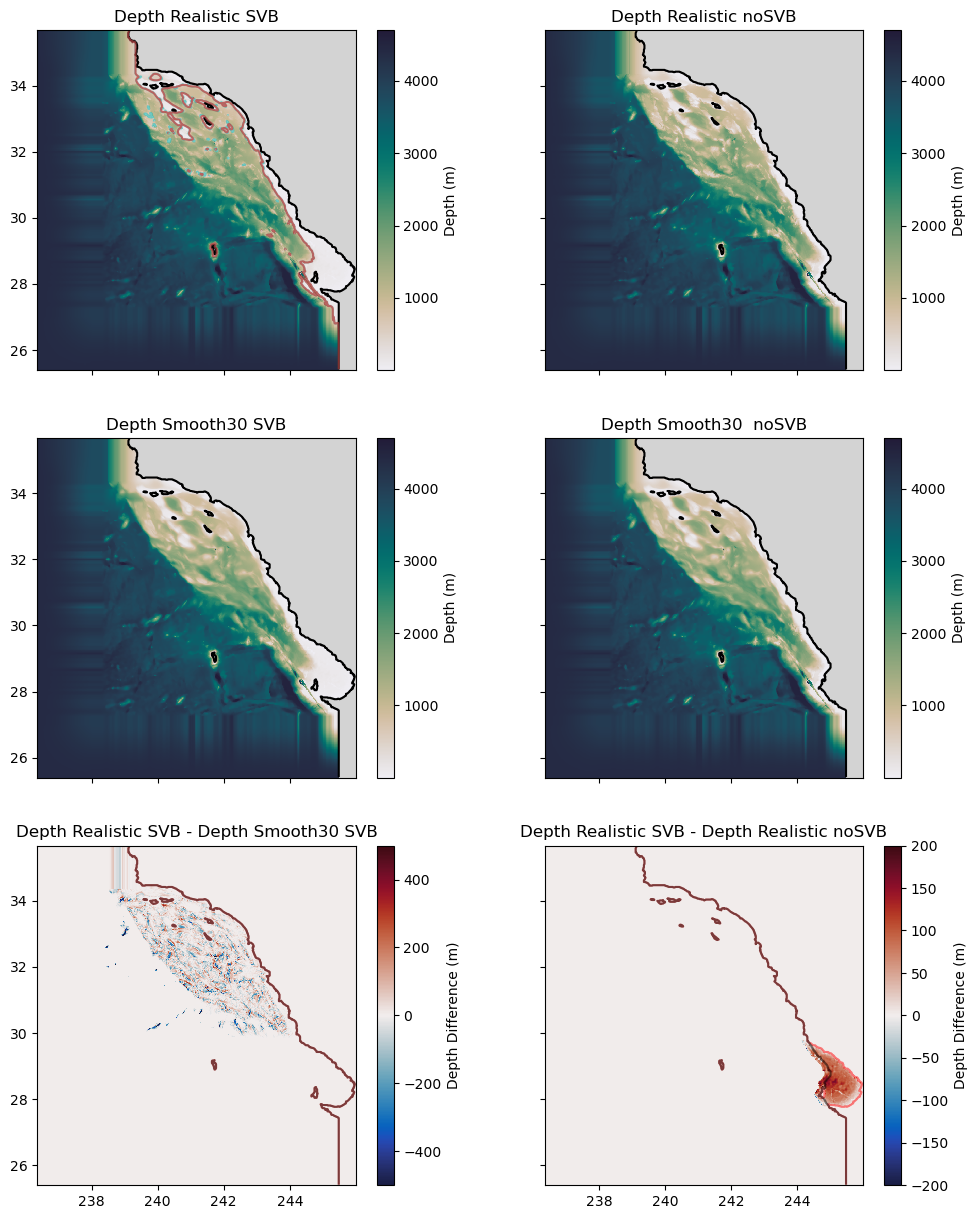

In [4]:
mask = np.where(df['Depth_realistic_plusSVB'].values == 0, True, False) 
maskno = np.where(df['Depth_realistic_minusSVB'].values == 0, True, False) 
cmap_bathy = cmo.cm.rain
cmap_diff = cmo.cm.balance

fig, ((ax, ax2), (ax3, ax4), (ax5, ax6)) = plt.subplots(3, 2, figsize=(12, 15), sharex=True, sharey=True)

for axx in [ax, ax2, ax3, ax4, ax5, ax6]:
    axx.set_fc('lightgrey')

pc = ax.pcolormesh(df.XC, df.YC, np.ma.masked_array(df['Depth_realistic_plusSVB'].values, mask=mask), cmap=cmap_bathy, shading='auto')
cn = ax.contour(df.XC, df.YC, df['Depth_realistic_plusSVB'].values, colors='k', levels=[0])
plt.colorbar(pc, ax=ax, label='Depth (m)')
ax.contour(df.XC, df.YC, df['Depth_realistic_plusSVB'].values, colors='c', levels=[500], alpha=0.5)
ax.contour(df.XC, df.YC, df['Depth_smooth30_plusSVB'].values, colors='r', levels=[500], alpha=0.5)
ax.set_title('Depth Realistic SVB')
pc2 = ax2.pcolormesh(df.XC, df.YC, np.ma.masked_array(df['Depth_realistic_minusSVB'].values, mask=maskno), cmap=cmap_bathy, shading='auto')
cn2 = ax2.contour(df.XC, df.YC, df['Depth_realistic_minusSVB'].values, colors='k', levels=[0])

plt.colorbar(pc2, ax=ax2, label='Depth (m)')
ax2.set_title('Depth Realistic noSVB')

pc3 = ax3.pcolormesh(df.XC, df.YC, np.ma.masked_array(df['Depth_smooth30_plusSVB'].values, mask=mask), cmap=cmap_bathy, shading='auto')
cn3 = ax3.contour(df.XC, df.YC, df['Depth_smooth30_plusSVB'].values, colors='k', levels=[0])
plt.colorbar(pc3, ax=ax3, label='Depth (m)')
ax3.set_title('Depth Smooth30 SVB')
pc4 = ax4.pcolormesh(df.XC, df.YC, np.ma.masked_array(df['Depth_smooth30_minusSVB'].values, mask=maskno), cmap=cmap_bathy, shading='auto')
cn4 = ax4.contour(df.XC, df.YC, df['Depth_smooth30_minusSVB'].values, colors='k', levels=[0])
plt.colorbar(pc4, ax=ax4, label='Depth (m)')
ax4.set_title('Depth Smooth30  noSVB')

pc5 = ax5.pcolormesh(df.XC, df.YC, df['Depth_realistic_plusSVB'].values-df['Depth_smooth30_plusSVB'].values, cmap=cmap_diff, shading='auto', vmin=-500, vmax=500)
plt.colorbar(pc5, ax=ax5, label='Depth Difference (m)')
cn5 = ax5.contour(df.XC, df.YC, df['Depth_realistic_plusSVB'].values, colors='r', levels=[0], alpha=0.5)
cn5b = ax5.contour(df.XC, df.YC, df['Depth_smooth30_plusSVB'].values, colors='k', levels=[0], alpha=0.5)

ax5.set_title('Depth Realistic SVB - Depth Smooth30 SVB')
pc6 = ax6.pcolormesh(df.XC, df.YC, df['Depth_realistic_plusSVB'].values-df['Depth_realistic_minusSVB'].values, cmap=cmap_diff, shading='auto', vmin=-200, vmax=200)
plt.colorbar(pc6, ax=ax6, label='Depth Difference (m)')
cn6 = ax6.contour(df.XC, df.YC, df['Depth_smooth30_plusSVB'].values, colors='r', levels=[0], alpha=0.5)
cn6b = ax6.contour(df.XC, df.YC, df['Depth_smooth30_minusSVB'].values, colors='k', levels=[0], alpha=0.5)

ax6.set_title('Depth Realistic SVB - Depth Realistic noSVB')

for axx in [ax, ax2, ax3, ax4, ax5, ax6]:
    axx.set_aspect('equal')

fig.savefig("../ctw_reruns_telescoped_west64_south72/model_configuration_summary/figures/bathy_comparison_final.png", dpi=300, bbox_inches='tight')

Text(0.5, 1.0, 'Depth Realistic SVB')

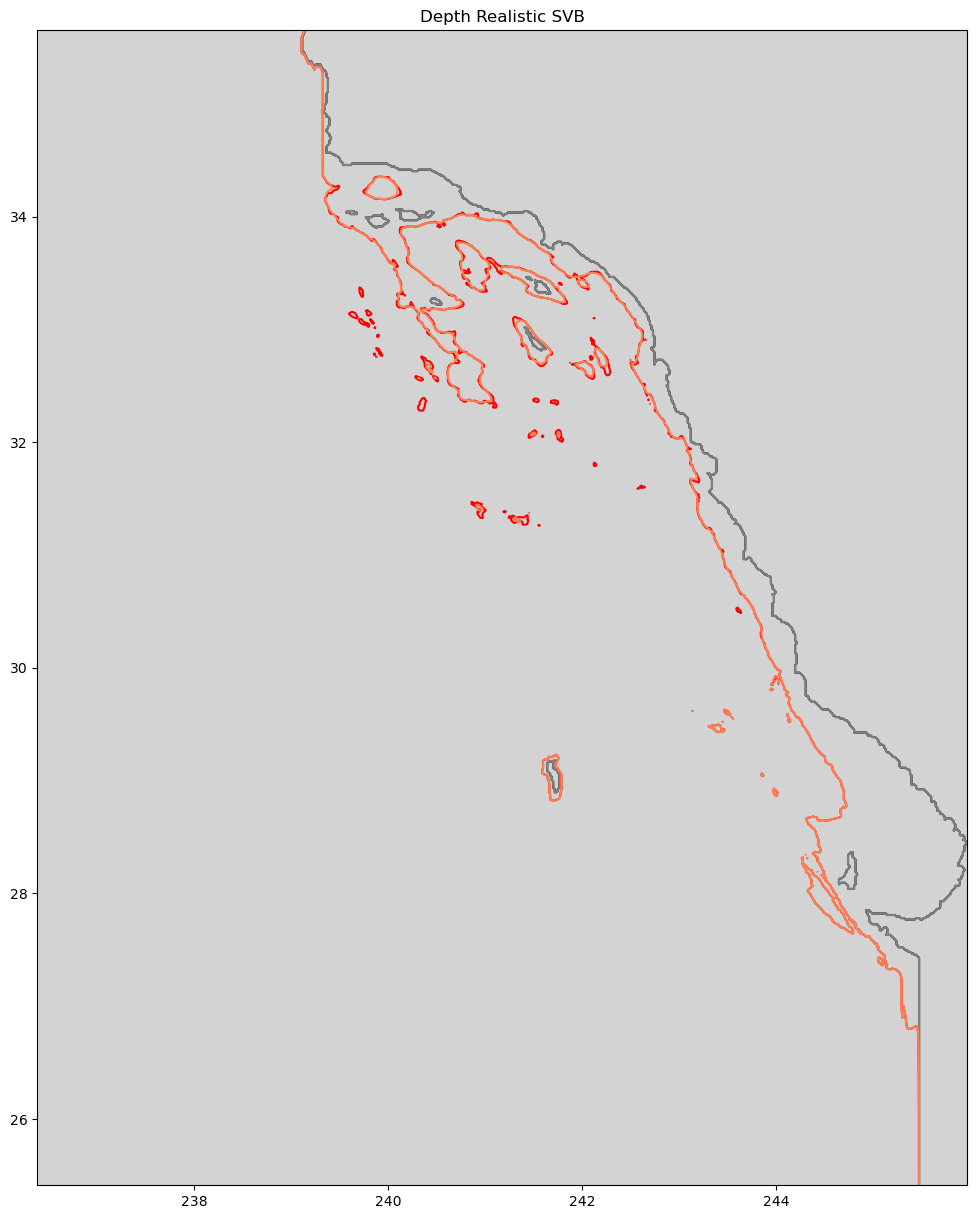

In [5]:
mask = np.where(df['Depth_realistic_plusSVB'].values == 0, True, False) 
maskno = np.where(df['Depth_realistic_minusSVB'].values == 0, True, False) 
cmap_bathy = cmo.cm.rain
cmap_diff = cmo.cm.balance

fig, ax = plt.subplots(1, 1, figsize=(12, 15), sharex=True, sharey=True)

for axx in [ax]:
    axx.set_fc('lightgrey')

#pc = ax.pcolormesh(df.XC, df.YC, np.ma.masked_array(df['Depth_realistic_plusSVB'].values, mask=mask), cmap=cmap_bathy, shading='auto')
cn = ax.contour(df.XC, df.YC, df['Depth_realistic_plusSVB'].values, colors=['k','r'], levels=[0,500])
cn = ax.contour(df.XC, df.YC, df['Depth_smooth30_plusSVB'].values, colors=['0.5','coral'], levels=[0,500])

ax.set_title('Depth Realistic SVB')


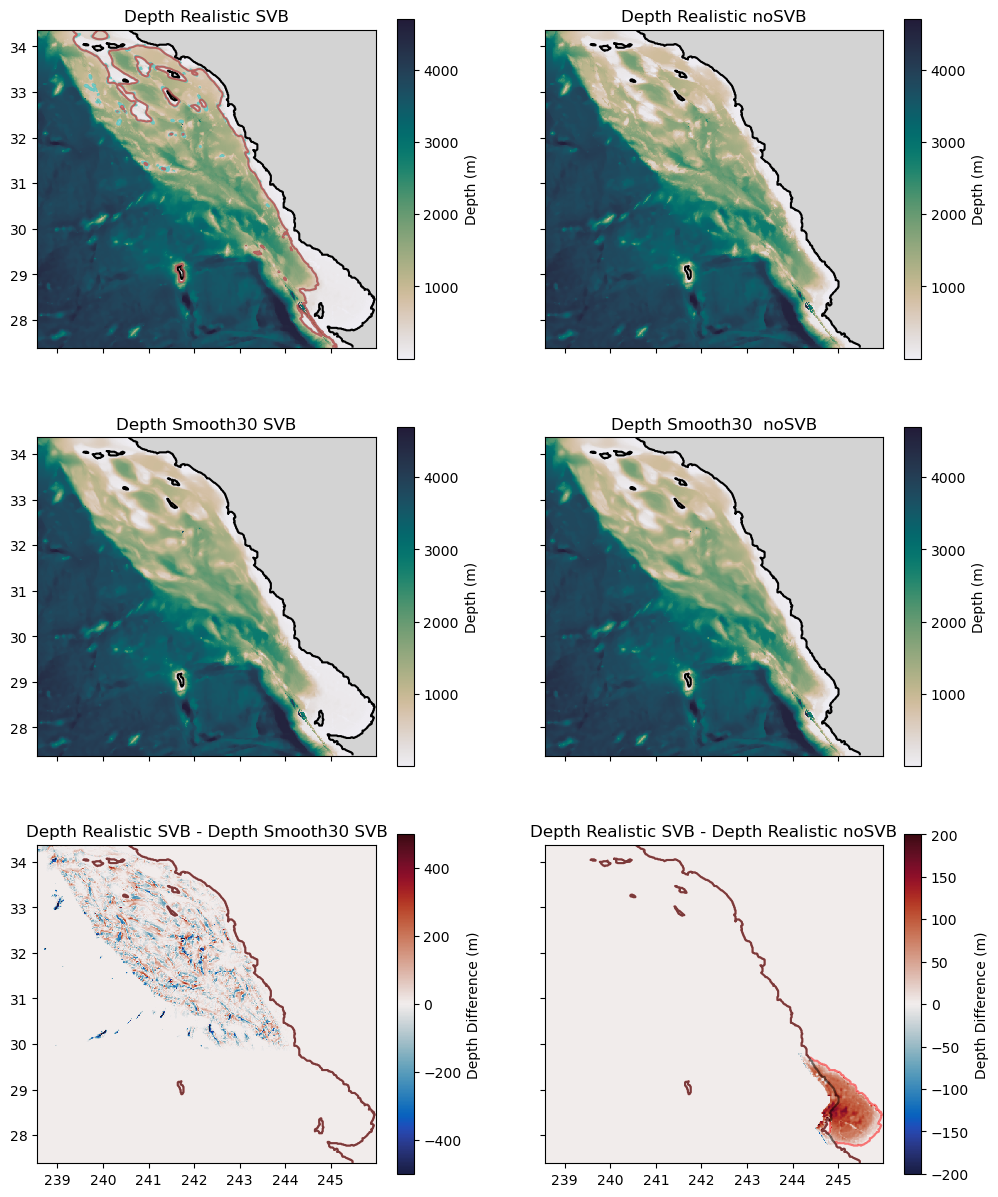

In [6]:
mask = np.where(df['Depth_realistic_plusSVB'].values == 0, True, False) 
maskno = np.where(df['Depth_realistic_minusSVB'].values == 0, True, False) 
cmap_bathy = cmo.cm.rain
cmap_diff = cmo.cm.balance

fig, ((ax, ax2), (ax3, ax4), (ax5, ax6)) = plt.subplots(3, 2, figsize=(12, 15), sharex=True, sharey=True)

for axx in [ax, ax2, ax3, ax4, ax5, ax6]:
    axx.set_fc('lightgrey')

pc = ax.pcolormesh(df.XC[100:], df.YC[100:-70], np.ma.masked_array(df['Depth_realistic_plusSVB'].values, mask=mask)[100:-70, 100:], cmap=cmap_bathy, shading='auto')
cn = ax.contour(df.XC[100:], df.YC[100:-70], df['Depth_realistic_plusSVB'].values[100:-70, 100:], colors='k', levels=[0])
plt.colorbar(pc, ax=ax, label='Depth (m)')
ax.contour(df.XC[100:], df.YC[100:-70], df['Depth_realistic_plusSVB'].values[100:-70, 100:], colors='c', levels=[500], alpha=0.5)
ax.contour(df.XC[100:], df.YC[100:-70], df['Depth_smooth30_plusSVB'].values[100:-70, 100:], colors='r', levels=[500], alpha=0.5)
ax.set_title('Depth Realistic SVB')
pc2 = ax2.pcolormesh(df.XC[100:], df.YC[100:-70], np.ma.masked_array(df['Depth_realistic_minusSVB'].values, mask=maskno)[100:-70, 100:], cmap=cmap_bathy, shading='auto')
cn2 = ax2.contour(df.XC[100:], df.YC[100:-70], df['Depth_realistic_minusSVB'].values[100:-70, 100:], colors='k', levels=[0])

plt.colorbar(pc2, ax=ax2, label='Depth (m)')
ax2.set_title('Depth Realistic noSVB')

pc3 = ax3.pcolormesh(df.XC[100:], df.YC[100:-70], np.ma.masked_array(df['Depth_smooth30_plusSVB'].values, mask=mask)[100:-70, 100:], cmap=cmap_bathy, shading='auto')
cn3 = ax3.contour(df.XC[100:], df.YC[100:-70], df['Depth_smooth30_plusSVB'].values[100:-70, 100:], colors='k', levels=[0])
plt.colorbar(pc3, ax=ax3, label='Depth (m)')
ax3.set_title('Depth Smooth30 SVB')
pc4 = ax4.pcolormesh(df.XC[100:], df.YC[100:-70], np.ma.masked_array(df['Depth_smooth30_minusSVB'].values, mask=maskno)[100:-70, 100:], cmap=cmap_bathy, shading='auto')
cn4 = ax4.contour(df.XC[100:], df.YC[100:-70], df['Depth_smooth30_minusSVB'].values[100:-70, 100:], colors='k', levels=[0])
plt.colorbar(pc4, ax=ax4, label='Depth (m)')
ax4.set_title('Depth Smooth30  noSVB')

pc5 = ax5.pcolormesh(df.XC[100:], df.YC[100:-70], (df['Depth_realistic_plusSVB'].values-df['Depth_smooth30_plusSVB'].values)[100:-70, 100:], cmap=cmap_diff, shading='auto', vmin=-500, vmax=500)
plt.colorbar(pc5, ax=ax5, label='Depth Difference (m)')
cn5 = ax5.contour(df.XC[100:], df.YC[100:-70], df['Depth_realistic_plusSVB'].values[100:-70, 100:], colors='r', levels=[0], alpha=0.5)
cn5b = ax5.contour(df.XC[100:], df.YC[100:-70], df['Depth_smooth30_plusSVB'].values[100:-70, 100:], colors='k', levels=[0], alpha=0.5)

ax5.set_title('Depth Realistic SVB - Depth Smooth30 SVB')
pc6 = ax6.pcolormesh(df.XC[100:], df.YC[100:-70], (df['Depth_realistic_plusSVB'].values-df['Depth_realistic_minusSVB'].values)[100:-70, 100:], cmap=cmap_diff, shading='auto', vmin=-200, vmax=200)
plt.colorbar(pc6, ax=ax6, label='Depth Difference (m)')
cn6 = ax6.contour(df.XC[100:], df.YC[100:-70], df['Depth_smooth30_plusSVB'].values[100:-70, 100:], colors='r', levels=[0], alpha=0.5)
cn6b = ax6.contour(df.XC[100:], df.YC[100:-70], df['Depth_smooth30_minusSVB'].values[100:-70, 100:], colors='k', levels=[0], alpha=0.5)

ax6.set_title('Depth Realistic SVB - Depth Realistic noSVB')

for axx in [ax, ax2, ax3, ax4, ax5, ax6]:
    axx.set_aspect('equal')

fig.savefig("../ctw_reruns_telescoped_west64_south72/model_configuration_summary/figures/bathy_comparison_nosponge_final.png", dpi=300, bbox_inches='tight')

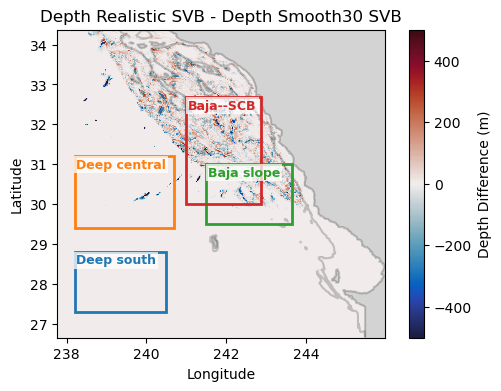

In [16]:
mask = np.where(df['Depth_realistic_plusSVB'].values == 0, True, False) 
maskno = np.where(df['Depth_realistic_minusSVB'].values == 0, True, False) 
cmap_bathy = cmo.cm.rain
cmap_diff = cmo.cm.balance

fig, ax5 = plt.subplots(1, 1, figsize=(6,4), sharex=True, sharey=True)

for axx in [ax5]:
    axx.set_fc('lightgrey')

pc5 = ax5.pcolormesh(df.XC[50:], df.YC[50:-70],
                     np.ma.masked_array((df['Depth_realistic_plusSVB'].values-df['Depth_smooth30_plusSVB'].values)[50:-70, 50:], mask=mask[50:-70, 50:]),
                     cmap=cmap_diff, shading='auto', vmin=-500, vmax=500)
plt.colorbar(pc5, ax=ax5, label='Depth Difference (m)')
cn5b = ax5.contour(df.XC[50:], df.YC[50:-70], df['Depth_realistic_plusSVB'].values[50:-70, 50:], colors='k', levels=[0, 500], alpha=0.2)
ax5.set_title('Depth Realistic SVB - Depth Smooth30 SVB')

for axx in [ax5]:
    axx.set_aspect('equal')



# Final spectral-sampling boxes:
# (west, east, south, north)
SPECTRAL_BOXES = {
    "Deep south": (
        -121.8,
        -119.5,
        27.3,
        28.8,
    ),
    "Deep central": (
        -121.8,
        -119.3,
        29.4,
        31.2,
    ),
    "Baja slope": (
        -118.5,
        -116.34700012207034,
        29.5,
        31.0,
    ),
    "Baja--SCB": (
        -119.0,
        -117.14231872558597,
        30.0,
        32.67774772644042,
    ),
}

uses_360_longitude = np.nanmax(df.XC) > 180.0
longitude_shift = 360.0 if uses_360_longitude else 0.0

# Use the standard matplotlib color cycle.
box_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

legend_handles = []

for color, (name, bounds) in zip(box_colors, SPECTRAL_BOXES.items()):
    west, east, south, north = bounds

    west_plot = west + longitude_shift
    east_plot = east + longitude_shift

    rectangle = Rectangle(
        (west_plot, south),
        east_plot - west_plot,
        north - south,
        facecolor="none",
        edgecolor=color,
        linewidth=2.0,
        linestyle="-",
        zorder=20,
    )
    ax5.add_patch(rectangle)

    # Label near the upper-left corner of each box.
    ax5.text(
        west_plot + 0.04,
        north - 0.04,
        name,
        color=color,
        fontsize=9,
        fontweight="bold",
        horizontalalignment="left",
        verticalalignment="top",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.75,
            "pad": 1.5,
        },
        zorder=21,
    )

    legend_handles.append(
        Line2D(
            [0],
            [0],
            color=color,
            linewidth=2.0,
            label=name,
        )
    )


ax5.set_xlabel("Longitude")
ax5.set_ylabel("Latitude")
fig.savefig("../ctw_reruns_telescoped_west64_south72/model_configuration_summary/figures/sampling_boxes.png", dpi=300, bbox_inches='tight')
